# Four-spacecraft timing of an electron hole
author: Louis Richard\
Velocity of an electron hole from the delays between the four MMS spacecraft, found by cross-correlation with `pyrf.c_4_v_xcorr` (irfu-matlab `c_4_v_xcorr` and `irf_4_v_xcorr_errors`), with the errors of Vogt et al. (2011). The event is the slow electron hole of Fig. 2 of Kamaletdinov et al. (2021), in the plasma sheet on 2017-08-04 at about 09:01:08.104 UT: a bipolar parallel electric field of about 8 mV/m, seen by MMS3, MMS4, MMS1 and MMS2, in that order, within 20 ms. The same function times boundaries, current sheets and shocks (see `example_mms_ipshocks` for `c_4_v` and the docstring of `c_4_v_xcorr` for the choice of `fit`).

Kamaletdinov, S. R., Hutchinson, I. H., Vasko, I. Y., Artemyev, A. V., Lotekar, A., & Mozer, F. S. (2021). Spacecraft observations and theoretical understanding of slow electron holes. *Physical Review Letters*, 127, 165101. https://doi.org/10.1103/PhysRevLett.127.165101

Vogt, J., Haaland, S., & Paschmann, G. (2011). Accuracy of multi-point boundary crossing time analysis. *Annales Geophysicae*, 29, 2239-2252. https://doi.org/10.5194/angeo-29-2239-2011

In [1]:
%matplotlib inline
import logging

import matplotlib.pyplot as plt
import numpy as np

from pyrfu import mms, pyrf
from pyrfu.plot import make_labels, use_pyrfu_style

logging.getLogger("pyrfu").setLevel(logging.WARNING)
use_pyrfu_style(usetex=False)

## Load data
Burst-mode magnetic field (FGM) and electric field (EDP, 8192 samples/s) of the four spacecraft, and their positions (MEC). `t_ref` is the time origin of Fig. 2 of Kamaletdinov et al. (2021).

In [2]:
tint = ["2017-08-04T09:01:07.950", "2017-08-04T09:01:08.250"]
t_ref = np.datetime64("2017-08-04T09:01:08.104", "ns")

options = dict(verbose=False, source="aws")
b_mms = [mms.get_data("b_gse_fgm_brst_l2", tint, i, **options) for i in range(1, 5)]
e_mms = [mms.get_data("e_gse_edp_brst_l2", tint, i, **options) for i in range(1, 5)]

tint_r = pyrf.extend_tint(tint, [-60, 60])
r_mms = [mms.get_data("r_gse_mec_srvy_l2", tint_r, i, **options) for i in range(1, 5)]

## Parallel electric field and separations along the magnetic field
The electron hole is seen in the electric field along the magnetic field. The separations of the spacecraft along and across the mean magnetic field are those of the diagram above Fig. 2a of Kamaletdinov et al. (2021).

In [3]:
# Parallel electric field on each spacecraft
e_par_mms = [pyrf.dec_par_perp(e_xyz, b_xyz)[0] for e_xyz, b_xyz in zip(e_mms, b_mms)]

# Mean magnetic field direction
b_avg = pyrf.avg_4sc([pyrf.resample(b_xyz, b_mms[0]) for b_xyz in b_mms])
b_hat = np.mean(b_avg.data, axis=0)
b_hat /= np.linalg.norm(b_hat)

# Separations from MMS1 along and across the magnetic field at t_ref
t_ref_ts = pyrf.ts_scalar(np.array([t_ref]), np.zeros(1))
r_xyz = np.array([pyrf.resample(r_gse, t_ref_ts).data[0] for r_gse in r_mms])
dr_par = (r_xyz - r_xyz[0]) @ b_hat
dr_perp = np.linalg.norm(r_xyz - r_xyz[0] - np.outer(dr_par, b_hat), axis=1)

print(f"Magnetic field direction (GSE): {np.round(b_hat, 3)}")
for i in range(1, 4):
    print(
        f"MMS{i + 1} - MMS1: {dr_par[i]:+6.2f} km along B, {dr_perp[i]:5.2f} km across"
    )

Magnetic field direction (GSE): [0.967 0.232 0.107]
MMS2 - MMS1:  -5.15 km along B, 10.68 km across
MMS3 - MMS1:  +7.92 km along B, 13.97 km across
MMS4 - MMS1:  +6.88 km along B, 13.70 km across


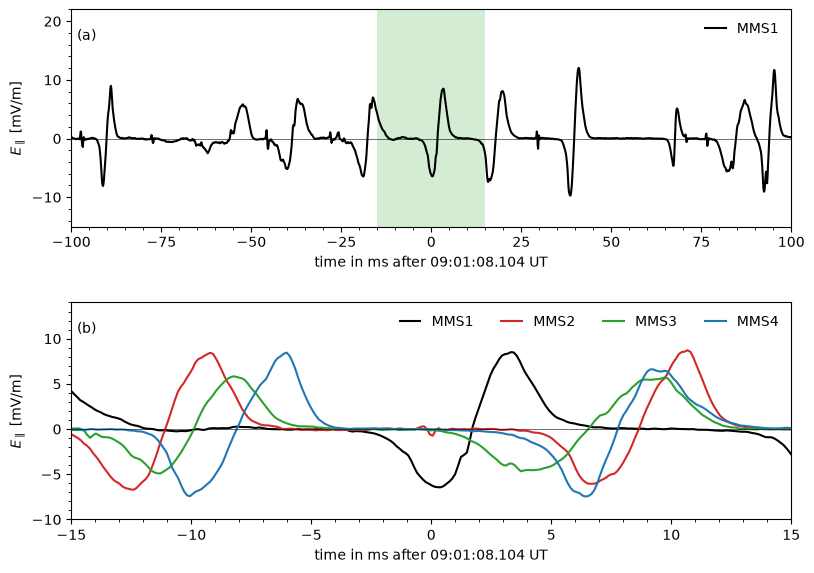

In [4]:
def ms_from_ref(inp):
    return (inp.time.data - t_ref).astype(np.int64) * 1e-6


colors = ["k", "tab:red", "tab:green", "tab:blue"]
label_options = dict(bbox=dict(facecolor="white", edgecolor="none", pad=1))
legend_options = dict(ncol=4, handlelength=1.5, loc="upper right", frameon=False)

f, axs = plt.subplots(2, 1, figsize=(9, 6))
f.subplots_adjust(left=0.1, right=0.9, bottom=0.1, top=0.95, hspace=0.35)

axs[0].plot(ms_from_ref(e_par_mms[0]), e_par_mms[0].data, color="k", label="MMS1")
axs[0].axvspan(-15, 15, color="tab:green", alpha=0.2, lw=0)
axs[0].set_xlim([-100, 100])
axs[0].set_ylim([-15, 22])
axs[0].legend(**legend_options)

for i, e_par in enumerate(e_par_mms):
    axs[1].plot(ms_from_ref(e_par), e_par.data, color=colors[i], label=f"MMS{i + 1}")

axs[1].set_xlim([-15, 15])
axs[1].set_ylim([-10, 14])
axs[1].legend(**legend_options)

for ax in axs:
    ax.axhline(0, color="k", lw=0.4)
    ax.set_ylabel("$E_{\\parallel}$ [mV/m]")
    ax.set_xlabel(f"time in ms after {str(t_ref)[11:23]} UT")

make_labels(axs, [0.008, 0.86], **label_options)
f.align_ylabels(axs)

## A train of electron holes: first guess of the delays
The electron holes come every 15-20 ms and look alike, so the delays must be searched near the right hole. Searching each delay within &pm;15 ms of zero (`max_lag=0.015`), as for an isolated structure, MMS2 and MMS4 are fitted to neighbouring holes, with correlations still close to 1:

In [5]:
# MMS1 sees the hole from about -1 to +6 ms: tint with a margin of a couple of widths
tint_eh = list(
    pyrf.datetime642iso8601(t_ref + np.array([-4, 8]) * np.timedelta64(1, "ms"))
)

res_wide = pyrf.c_4_v_xcorr(tint_eh, e_par_mms, r_mms, max_lag=0.015, fit="scale")
print(f"Delays to MMS1 (ms): {np.round(res_wide['tau'][1:] * 1e3, 2)}")
print(f"Correlations with the pattern: {np.round(res_wide['corr'], 3)}")
print(f"Speed: {res_wide['speed']:.0f} km/s")

Delays to MMS1 (ms): [-12.76 -11.57   6.14]
Correlations with the pattern: [0.997 0.998 0.998 0.993]
Speed: 612 km/s


Instead, the delays are searched within &pm;3 ms (`max_lag`, less than half the spacing of the holes) of a first guess (`tau`): the delays between the positive peaks of $E_{\parallel}$ within &pm;15 ms of `t_ref`.

In [6]:
tint_peak = list(
    pyrf.datetime642iso8601(t_ref + np.array([-15, 15]) * np.timedelta64(1, "ms"))
)
t_peak = [
    pyrf.time_clip(e_par, tint_peak).idxmax(dim="time").data for e_par in e_par_mms
]
tau_0 = [(t - t_peak[0]).astype(np.int64) * 1e-9 for t in t_peak]
print(
    f"First guess of the delays to MMS1 (ms): {np.round(np.array(tau_0[1:]) * 1e3, 2)}"
)

First guess of the delays to MMS1 (ms): [  7.37 -11.55  -9.34]


## Timing by cross-correlation
The delays are fitted around the first guess, with a scale per spacecraft (`fit="scale"`): an electron hole is seen with different amplitudes by spacecraft at different distances from its centre. The velocity and its errors follow from the delays, their covariance and the positions of the spacecraft (Vogt et al., 2011). The noise is low here, so a low-pass filter (`f_max`) changes nothing.

In [7]:
res = pyrf.c_4_v_xcorr(tint_eh, e_par_mms, r_mms, max_lag=0.003, tau=tau_0, fit="scale")

dtau2 = res["dtau2"]

for i in range(1, 4):
    d_tau = np.sqrt(dtau2[i, i] + dtau2[0, 0] - 2 * dtau2[0, i])
    print(
        f"MMS{i + 1}: delay {res['tau'][i] * 1e3:+7.3f} +- {d_tau * 1e3:.3f} ms, "
        f"scale {res['scale'][i]:.2f}, correlation {res['corr'][i]:.3f}"
    )

n_dot_b = res["n"] @ b_hat
print(f"Speed: {res['speed']:.0f} +- {res['d_speed']:.0f} km/s")
print(f"Direction (GSE): {np.round(res['n'], 3)}, n.b = {n_dot_b:.4f}")
print(f"Angle to -B: {np.degrees(np.arccos(-n_dot_b)):.1f} deg")
print(f"Direction errors: {np.round(np.degrees(res['d_theta']), 2)} deg")

MMS2: delay  +6.982 +- 0.049 ms, scale 0.97, correlation 0.997
MMS3: delay -11.560 +- 0.029 ms, scale 0.71, correlation 0.997
MMS4: delay  -9.755 +- 0.046 ms, scale 0.98, correlation 0.995
Speed: 712 +- 1 km/s
Direction (GSE): [-0.961 -0.251 -0.119], n.b = -0.9997
Angle to -B: 1.3 deg
Direction errors: [0.09 0.16] deg


The electron hole moves antiparallel to the magnetic field at about 710 km/s. Kamaletdinov et al. (2021) assume a propagation along the magnetic field and divide the separation along it by the delay, for MMS1 with each other spacecraft; with the delays above:

In [8]:
v_par_pairs = dr_par[1:] / res["tau"][1:]
v_par_paper = [-760, -695, -705]

for i in range(3):
    print(
        f"MMS1-MMS{i + 2}: {v_par_pairs[i]:.0f} km/s (Kamaletdinov et al. 2021: {v_par_paper[i]} km/s)"
    )

MMS1-MMS2: -738 km/s (Kamaletdinov et al. 2021: -760 km/s)
MMS1-MMS3: -685 km/s (Kamaletdinov et al. 2021: -695 km/s)
MMS1-MMS4: -705 km/s (Kamaletdinov et al. 2021: -705 km/s)


The errors account for the noise only, not for an electron hole that is not planar or changes between the spacecraft: the spread of the two-spacecraft speeds (&pm;30 km/s) is larger than the error of the speed.

## The fit
(a) The parallel electric field of each spacecraft shifted by its delay and divided by its scale, with the pattern they are fitted to. (b) The electrostatic potential of the electron hole on each spacecraft, $\phi = \int E_{\parallel} V_{\parallel} dt$ over the hole, with $V_{\parallel}$ its speed along the magnetic field, as Fig. 2b of Kamaletdinov et al. (2021).

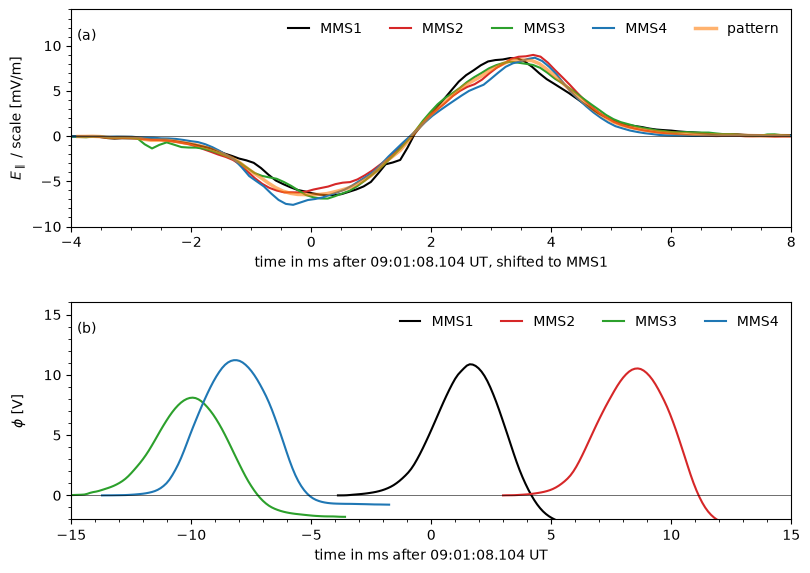

In [9]:
v_par = res["speed"] / n_dot_b

f, axs = plt.subplots(2, 1, figsize=(9, 6))
f.subplots_adjust(left=0.1, right=0.9, bottom=0.1, top=0.95, hspace=0.35)

for i, e_par in enumerate(e_par_mms):
    t_shift = ms_from_ref(e_par) - res["tau"][i] * 1e3
    axs[0].plot(
        t_shift, e_par.data / res["scale"][i], color=colors[i], label=f"MMS{i + 1}"
    )

axs[0].plot(
    ms_from_ref(res["pattern"]),
    res["pattern"].data,
    color="tab:orange",
    lw=2.5,
    alpha=0.6,
    label="pattern",
)
axs[0].set_xlim([-4, 8])
axs[0].set_ylim([-10, 14])
axs[0].set_ylabel("$E_{\\parallel}$ / scale [mV/m]")
axs[0].set_xlabel(f"time in ms after {str(t_ref)[11:23]} UT, shifted to MMS1")
axs[0].legend(**dict(legend_options, ncol=5))

for i, e_par in enumerate(e_par_mms):
    # Over the hole on each spacecraft: tint_eh shifted by the delay
    tint_i = pyrf.extend_tint(tint_eh, [res["tau"][i], res["tau"][i]])
    e_win = pyrf.time_clip(e_par, tint_i)
    d_t = np.diff(e_win.time.data).astype(np.int64) * 1e-9
    phi = np.concatenate([[0.0], np.cumsum(e_win.data[1:] * v_par * d_t)])
    axs[1].plot(ms_from_ref(e_win), phi, color=colors[i], label=f"MMS{i + 1}")

axs[1].set_xlim([-15, 15])
axs[1].set_ylim([-2, 16])
axs[1].set_ylabel("$\\phi$ [V]")
axs[1].set_xlabel(f"time in ms after {str(t_ref)[11:23]} UT")
axs[1].legend(**legend_options)

for ax in axs:
    ax.axhline(0, color="k", lw=0.4)

make_labels(axs, [0.008, 0.86], **label_options)
f.align_ylabels(axs)